# INCT SiMAI - Fase 2: Coleta, Preparação e Análise Exploratória (EDA)
**Disciplina:** Coleta, Preparação e Análise de Dados

**Objetivo:** Este notebook documenta o pipeline de dados responsável pela extração, limpeza e análise estatística da precipitação em Porto Alegre, focando no período crítico de abril e maio de 2024.

**Justificativa Metodológica:** Devido à instabilidade crônica dos servidores da Agência Nacional de Águas (ANA), optou-se pela utilização da API oficial da Open-Meteo. A arquitetura emprega um proxy local em Flask para isolar a aplicação de falhas diretas de rede, garantindo maior resiliência na coleta.

In [1]:
# 1. Instalação e Importação de Bibliotecas
# Descomente a linha abaixo caso precise instalar as dependências no ambiente virtual
# !pip install pandas requests matplotlib seaborn flask

import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Configurações visuais e de exibição do Pandas
pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")
print("Bibliotecas importadas e configuradas com sucesso!")

Bibliotecas importadas e configuradas com sucesso!


## 2. Arquitetura de Coleta: API Flask (Proxy Meteorológico)
Para garantir a reprodutibilidade e evitar chamadas excessivas diretas ao servidor da Open-Meteo, criamos um endpoint local. O código abaixo gera o arquivo `api_flask.py`. 

**Nota de Execução:** É necessário rodar `python api_flask.py` em um terminal separado (porta 5001) antes de prosseguir com as células de coleta.

In [2]:
%%writefile api_flask.py
from flask import Flask, jsonify
import requests

app = Flask(__name__)
app.config['JSON_AS_ASCII'] = False

@app.route("/api/meteo", methods=["GET"])
def get_meteo():
    # Coordenadas: Porto Alegre (Lat: -30.0332, Lon: -51.2300)
    # Período: 01/04/2024 a 31/05/2024
    url = "https://archive-api.open-meteo.com/v1/archive?latitude=-30.0332&longitude=-51.2300&start_date=2024-04-01&end_date=2024-05-31&daily=precipitation_sum,rain_sum&timezone=America%2FSao_Paulo"
    
    try:
        # Adicionado timeout de 15s para evitar travamento da requisição
        res = requests.get(url, timeout=15)
        res.raise_for_status() # Levanta exceção para códigos HTTP de erro (4xx, 5xx)
        return jsonify(res.json())
    except requests.exceptions.RequestException as e:
        # Tratamento de erro rigoroso para falhas na API externa
        return jsonify({"erro": "Falha ao comunicar com Open-Meteo", "detalhes": str(e)}), 502

if __name__ == "__main__":
    app.run(port=5001, debug=True)


Writing api_flask.py


## 3. Módulos de Ingestão e Limpeza de Dados
As funções abaixo encapsulam a lógica de extração via Flask e a preparação do dataset. A tipagem explícita e a verificação de nulos são fundamentais para evitar erros em cascata durante o cálculo das estatísticas.

In [3]:
def coletar_dados_flask(rota):
    """Realiza requisição GET ao proxy Flask local."""
    url = f"http://127.0.0.1:5001{rota}"
    try:
        res = requests.get(url, timeout=10)
        if res.status_code == 200:
            return res.json()
        else:
            print(f"Aviso: A API retornou status {res.status_code}. Mensagem: {res.text}")
    except requests.exceptions.ConnectionError:
        print(f"Erro de Conexão: O Flask não está rodando na porta 5001. Execute 'python api_flask.py' no terminal.")
    except Exception as e:
        print(f"Erro inesperado durante a coleta: {e}")
    return None

def limpar_dados_meteo(df):
    """Aplica transformações estruturais e tipagem na base de dados bruta."""
    if df is None or df.empty: 
        return pd.DataFrame()
    
    df_limpo = df.copy()
    
    # 1. Tratamento de valores ausentes (Drop apenas se faltar data ou precipitação)
    df_limpo = df_limpo.dropna(subset=['time', 'precipitation_sum'])
    
    # 2. Remoção de possíveis duplicações temporais
    df_limpo = df_limpo.drop_duplicates(subset=['time'])
    
    # 3. Tipagem explícita
    df_limpo['time'] = pd.to_datetime(df_limpo['time'])
    df_limpo['precipitation_sum'] = pd.to_numeric(df_limpo['precipitation_sum'])
    
    # 4. Ordenação cronológica (garantia para séries temporais)
    df_limpo = df_limpo.sort_values('time').reset_index(drop=True)
    
    return df_limpo

## 4. Inspeção dos Dados (Brutos vs. Limpos)
Validação visual e estrutural do dataframe antes e após o pipeline de limpeza.

In [4]:
# Ingestão dos dados
json_meteo = coletar_dados_flask("/api/meteo")

if json_meteo and 'daily' in json_meteo:
    df_meteo_bruto = pd.DataFrame(json_meteo['daily'])
    print("=== OPEN-METEO (DADOS BRUTOS) ===")
    display(df_meteo_bruto.head(3))
    print("\n--- INFO METEO BRUTO ---")
    df_meteo_bruto.info()
    
    # Limpeza dos dados
    df_meteo_limpo = limpar_dados_meteo(df_meteo_bruto)
    print("\n\n=== OPEN-METEO (DADOS LIMPOS) ===")
    display(df_meteo_limpo.head(3))
    print("\n--- INFO METEO LIMPO ---")
    df_meteo_limpo.info()
else:
    print("Falha ao processar JSON ou dados indisponíveis. Verifique o servidor Flask.")
    df_meteo_limpo = pd.DataFrame() # DataFrame vazio para evitar quebra nas células seguintes

=== OPEN-METEO (DADOS BRUTOS) ===


,precipitation_sum,rain_sum,time
0,0.1,0.1,2024-04-01
1,0.6,0.6,2024-04-02
2,0.0,0.0,2024-04-03



--- INFO METEO BRUTO ---
<class 'pandas.DataFrame'>
RangeIndex: 61 entries, 0 to 60
Data columns (total 3 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   precipitation_sum  61 non-null     float64
 1   rain_sum           61 non-null     float64
 2   time               61 non-null     str    
dtypes: float64(2), str(1)
memory usage: 1.6 KB


=== OPEN-METEO (DADOS LIMPOS) ===


,precipitation_sum,rain_sum,time
0,0.1,0.1,2024-04-01
1,0.6,0.6,2024-04-02
2,0.0,0.0,2024-04-03



--- INFO METEO LIMPO ---
<class 'pandas.DataFrame'>
RangeIndex: 61 entries, 0 to 60
Data columns (total 3 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   precipitation_sum  61 non-null     float64       
 1   rain_sum           61 non-null     float64       
 2   time               61 non-null     datetime64[us]
dtypes: datetime64[us](1), float64(2)
memory usage: 1.6 KB


## 5. Estatísticas Descritivas e Detecção de Eventos Extremos
Nesta etapa calculamos métricas de tendência central, dispersão e percentis. 

**Justificativa Estatística para Outliers:** Em hidrologia, utilizamos o limite superior do **Intervalo Interquartil (IQR)** não para encontrar "erros" na base, mas sim para detectar anomalias meteorológicas severas. Os valores que ultrapassam o limite `Q3 + 1.5 * IQR` representam os picos pluviométricos (eventos extremos) responsáveis por saturar o solo e elevar drasticamente a cota dos rios.

*Nota: O limite inferior (Q1 - 1.5 * IQR) foi deliberadamente omitido, visto que precipitações não assumem valores negativos.*

In [5]:
if not df_meteo_limpo.empty:
    serie_chuva = df_meteo_limpo['precipitation_sum']
    
    # Métricas tradicionais e limiares de risco
    media = serie_chuva.mean()
    mediana = serie_chuva.median()
    desvio_padrao = serie_chuva.std()
    p90 = serie_chuva.quantile(0.90)
    p95 = serie_chuva.quantile(0.95)
    
    # Cálculo estatístico do IQR para detecção unilateral de chuva extrema
    q1 = serie_chuva.quantile(0.25)
    q3 = serie_chuva.quantile(0.75)
    iqr = q3 - q1
    limite_superior = q3 + 1.5 * iqr
    
    # Filtragem e isolamento dos dias anômalos
    outliers = df_meteo_limpo[df_meteo_limpo['precipitation_sum'] > limite_superior]
    
    print("=== RESUMO ESTATÍSTICO DA PRECIPITAÇÃO (ABR-MAI/2024) ===")
    print(f" • Observações válidas: {len(serie_chuva)} dias")
    print(f" • Média diária: {media:.2f} mm")
    print(f" • Mediana diária: {mediana:.2f} mm")
    print(f" • Desvio Padrão (Volatilidade): {desvio_padrao:.2f} mm")
    print(f" • Percentil 90 (P90): {p90:.2f} mm")
    print(f" • Percentil 95 (P95 - Limiar Crítico): {p95:.2f} mm")
    print(f" • Limite Superior para Anomalias (IQR): {limite_superior:.2f} mm\n")
    
    print("=== ANÁLISE DE EVENTOS EXTREMOS (OUTLIERS) ===")
    print(f"Total de dias identificados acima do limite IQR: {len(outliers)}")
    
    if not outliers.empty:
        print("\nDetalhamento dos dias críticos:")
        for _, row in outliers.iterrows():
            print(f" - Data: {row['time'].strftime('%d/%m/%Y')} | Volume Acumulado: {row['precipitation_sum']} mm")

=== RESUMO ESTATÍSTICO DA PRECIPITAÇÃO (ABR-MAI/2024) ===
 • Observações válidas: 61 dias
 • Média diária: 9.74 mm
 • Mediana diária: 0.90 mm
 • Desvio Padrão (Volatilidade): 17.67 mm
 • Percentil 90 (P90): 33.20 mm
 • Percentil 95 (P95 - Limiar Crítico): 48.90 mm
 • Limite Superior para Anomalias (IQR): 28.00 mm

=== ANÁLISE DE EVENTOS EXTREMOS (OUTLIERS) ===
Total de dias identificados acima do limite IQR: 8

Detalhamento dos dias críticos:
 - Data: 29/04/2024 | Volume Acumulado: 58.2 mm
 - Data: 30/04/2024 | Volume Acumulado: 86.0 mm
 - Data: 01/05/2024 | Volume Acumulado: 48.9 mm
 - Data: 02/05/2024 | Volume Acumulado: 56.2 mm
 - Data: 11/05/2024 | Volume Acumulado: 30.0 mm
 - Data: 12/05/2024 | Volume Acumulado: 37.1 mm
 - Data: 23/05/2024 | Volume Acumulado: 39.6 mm
 - Data: 27/05/2024 | Volume Acumulado: 33.2 mm


## 6. Análise Exploratória de Dados (EDA) - Séries Temporais
O gráfico de barras abaixo espacializa o volume pluviométrico no tempo. Foram incluídas linhas de referência estratificando o **Percentil 95** e o **Limite de Outliers (IQR)**, facilitando a identificação visual dos picos que levaram à crise de maio de 2024.

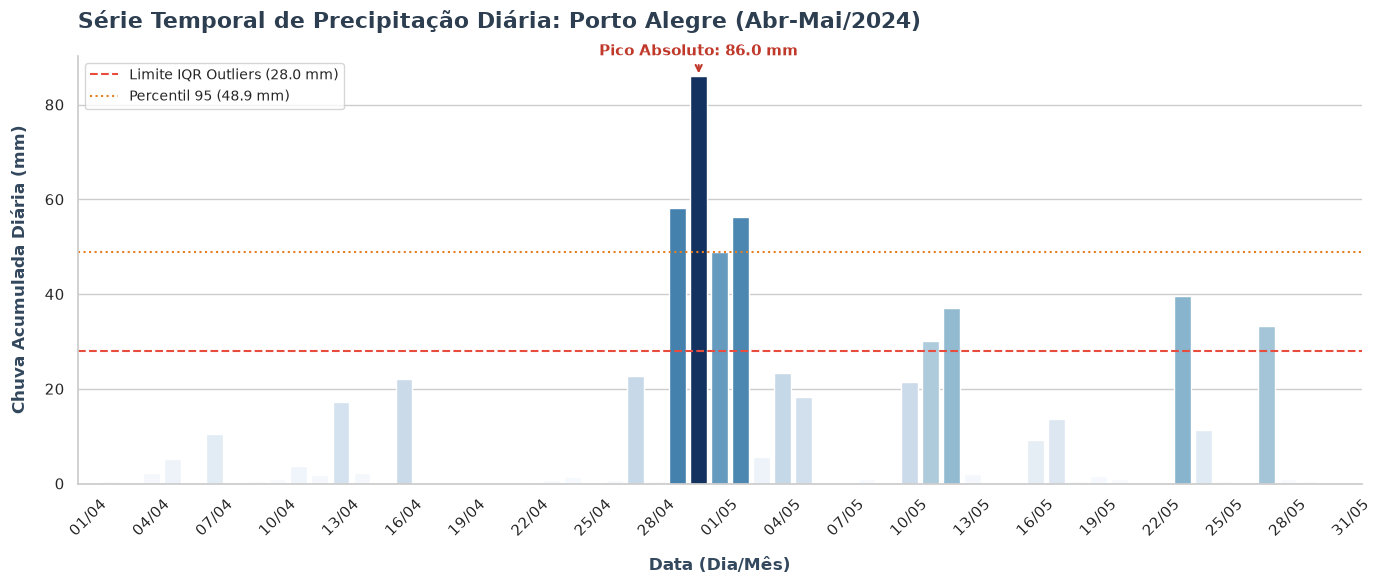

In [6]:
if not df_meteo_limpo.empty:
    # Configuração de design minimalista (removendo bordas superior e direita)
    sns.set_theme(style="whitegrid", rc={"axes.spines.top": False, "axes.spines.right": False})
    fig, ax = plt.subplots(figsize=(14, 6))
    
    df_meteo_graf = df_meteo_limpo.copy()
    # Formatando para exibição limpa sem alterar o tipo original do dado
    df_meteo_graf['data_str'] = df_meteo_graf['time'].dt.strftime('%d/%m')
    
    # Construção do Barplot com intensidade de cor ligada ao volume de chuva
    sns.barplot(
        data=df_meteo_graf, 
        x='data_str', 
        y='precipitation_sum', 
        palette="Blues", 
        hue='precipitation_sum', 
        legend=False,
        ax=ax
    )
    
    # Inserção das linhas analíticas (Limiares Estatísticos)
    ax.axhline(limite_superior, color='#e74c3c', linestyle='--', linewidth=1.5, label=f'Limite IQR Outliers ({limite_superior:.1f} mm)')
    ax.axhline(p95, color='#e67e22', linestyle=':', linewidth=1.5, label=f'Percentil 95 ({p95:.1f} mm)')
    ax.legend(loc='upper left', frameon=True, fontsize=10)
    
    # Tipografia e espaçamento
    ax.set_title('Série Temporal de Precipitação Diária: Porto Alegre (Abr-Mai/2024)', 
                 fontsize=16, fontweight='bold', color='#2c3e50', pad=20, loc='left')
    ax.set_xlabel('Data (Dia/Mês)', fontsize=12, fontweight='bold', color='#34495e', labelpad=12)
    ax.set_ylabel('Chuva Acumulada Diária (mm)', fontsize=12, fontweight='bold', color='#34495e', labelpad=12)
    
    # Redução de ruído no eixo X: exibir apenas rótulos intervalados
    for ind, label in enumerate(ax.get_xticklabels()):
        if ind % 3 == 0:
            label.set_visible(True)
            label.set_rotation(45)
        else:
            label.set_visible(False)
            
    # Destaca automaticamente o pico absoluto da série
    max_idx = df_meteo_graf['precipitation_sum'].idxmax()
    max_val = df_meteo_graf['precipitation_sum'].max()
    ax.annotate(f'Pico Absoluto: {max_val:.1f} mm', 
                xy=(max_idx, max_val), 
                xytext=(0, 15), 
                textcoords='offset points',
                ha='center', 
                fontsize=11, 
                fontweight='bold', 
                color='#c0392b',
                arrowprops=dict(arrowstyle='->', color='#c0392b', lw=1.5))
    
    plt.tight_layout()
    plt.show()

## 7. Interpretação dos Resultados e Limitações

**Interpretação Meteorológica:**
A análise exploratória comprova uma forte assimetria no comportamento pluviométrico de Porto Alegre entre abril e maio de 2024. A discrepância entre a média e a mediana evidencia que o período foi marcado por muitos dias de chuva fraca ou estiagem, interrompidos por eventos de precipitação severa contínua. 

Os valores identificados como **outliers estatísticos (superiores a Q3 + 1.5*IQR)** agruparam-se especificamente no final de abril e nos primeiros dias de maio. Estatisticamente, essa anomalia persistente representa o esgotamento da capacidade de infiltração do solo, configurando-se como o forte indicador meteorológico (fator gerador) da rápida elevação dos rios que compõem a bacia hidrográfica local, justificando o foco desta etapa do projeto INCT SiMAI.

**Limitações Metodológicas:**
1. **Ponto Cêntrico vs. Bacia:** Os dados extraídos da Open-Meteo refletem coordenadas específicas (Porto Alegre). Condições hidrológicas de enchentes frequentemente dependem de chuvas ocorridas à montante (cabeceiras dos rios Taquari, Caí e Jacuí) que não estão cobertas nesta coordenada única.
2. **Causalidade Estatística:** Embora haja correspondência temporal entre os outliers pluviométricos e os eventos de cheia, esta análise isolada **não estabelece relação direta de causalidade** hidrodinâmica, pois o nível do rio (que será integrado na próxima fase) também depende da topografia, maré da Lagoa dos Patos e obstrução urbana.